# 01. 배치 수행시간 및 기존 데이터 분할 검증

- 목적: 고정 초기 30분 조건의 적절성 확인, 기존 Train/Test 구성 및 수율 분포 검증
- 범위: 전체 제품의 로그 수행시간 확인, 기존 ML 대상 Code 13/17/23의 기존 분할 재현
- 이번 단계에서는 모델을 학습하지 않으며, 원본 및 기존 결과 파일을 변경하지 않는다.
- 수행시간은 최초~최종 유효 로그 시각의 차이로 정의한다. 실제 생산시간이나 작업시간과 동일하다고 단정하지 않는다.
- 기존 분할을 진단하기 위한 탐색용 Notebook이다. 기존 Test 결과는 이미 확인했으므로 향후 독립 최종 평가로 간주할 수 없다.

**Revision v2 (2026-11-25):** 두 timestamp 형식 통합, 수집 간격 진단, 날짜 파싱 실패 및 배치 커버리지 검증. 결과는 `01_batch_audit_v2`에 별도 저장한다.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import sys
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data' / 'Laboratory.csv').exists()), None)
assert ROOT is not None, 'yield_experiment 폴더 또는 notebooks 폴더에서 실행하세요.'
DATA = ROOT / 'data'
OUT = ROOT / 'results' / 'revision_20261125' / '01_batch_audit_v2'
OUT.mkdir(parents=True, exist_ok=True)
KEY = ['batch', 'code']
ML_CODES = [13, 17, 23]
SEED = 42
print('Root:', ROOT)
print('Python:', sys.version.split()[0], 'pandas:', pd.__version__, 'numpy:', np.__version__, 'sklearn:', sklearn.__version__)
for p in [DATA / 'Laboratory.csv', DATA / 'Process.csv', DATA / 'Process.zip']:
    assert p.is_file(), p
    with p.open('rb') as f:
        digest = hashlib.file_digest(f, 'sha256').hexdigest()
    print(p.name, p.stat().st_size, 'bytes', 'SHA256:', digest)
print('Notebook revision: v2 | dual timestamp formats')
print('Output:', OUT)

Root: /Users/park-inki/Desktop/SKALA-yield-model/yield_experiment
Python: 3.12.14 pandas: 2.2.3 numpy: 2.3.5 sklearn: 1.8.0
Laboratory.csv 293492 bytes SHA256: a3b0f16c7c3fa8052b38d767e38fda731a751acc4ec139b52d01577b32dc6483
Process.csv 257208 bytes SHA256: 68382e88104beb679acf66d0ec35177e0880e67c7a3d7e72dc60b1e3388410ce
Process.zip 29811605 bytes SHA256: 8a401f1c7ac9880c763e3350f595c45c90487c0950db48caa9cda729582f5c25
Notebook revision: v2 | dual timestamp formats
Output: /Users/park-inki/Desktop/SKALA-yield-model/yield_experiment/results/revision_20261125/01_batch_audit_v2


## 1. 배치 단위 데이터 점검
Laboratory.csv와 Process.csv의 배치/제품 키가 일대일인지 확인한다. Process.csv의 최종 집계값은 예측 입력으로 사용하지 않는다.

In [2]:
lab = pd.read_csv(DATA / 'Laboratory.csv', sep=';')
process = pd.read_csv(DATA / 'Process.csv', sep=';')
for name, frame in [('Laboratory', lab), ('Process', process)]:
    print(name, frame.shape, '제품 수:', frame.code.nunique(), '중복 키:', frame.duplicated(KEY).sum())
    assert not frame[KEY].isna().any().any(), f'{name}: missing key'
    assert not frame.duplicated(KEY).any(), f'{name}: duplicate key'
key_audit = lab[KEY].merge(process[KEY], on=KEY, how='outer', indicator=True, validate='one_to_one')
display(key_audit['_merge'].value_counts().to_frame('n'))
assert key_audit['_merge'].eq('both').all(), '배치 키 불일치: 원인 점검 필요'
lab['tbl_yield'] = pd.to_numeric(lab['tbl_yield'], errors='coerce')
display(lab.groupby('code').tbl_yield.agg(['size','count','mean','std','min','median','max']))

Laboratory (1005, 55) 제품 수: 25 중복 키: 0
Process (1005, 35) 제품 수: 25 중복 키: 0


,n
_merge,
both,1005
left_only,0
right_only,0


,size,count,mean,std,min,median,max
code,,,,,,,
1,95,95,97.628737,1.257351,91.288,97.7360,100.000
2,17,17,98.657235,0.758582,96.503,98.8170,99.621
3,16,16,98.735625,0.587618,97.630,98.6735,99.526
4,22,22,97.801818,1.037105,95.906,97.9535,99.338
5,3,3,97.509667,1.238649,96.206,97.6520,98.671
6,2,2,98.577500,0.886005,97.951,98.5775,99.204
7,8,8,96.956625,2.933235,90.431,97.6695,99.621
8,2,2,97.882000,0.219203,97.727,97.8820,98.037
9,4,4,96.958000,0.310269,96.578,96.9580,97.338


## 2. 시계열 로그 수행시간 및 품질 점검
제품별 ZIP 로그에서 배치별 첫 시각, 마지막 시각, 행 수, 유효 시각 수, 중복 시각 수, campaign 수를 추출한다. 시각이 같거나 누락된 경우 실제 생산 기록과의 차이를 추가 확인해야 한다.
두 날짜 형식을 명시적으로 처리하고, 동일 배치 내 중복을 제외한 연속 시각 간격 중앙값을 진단한다. 긴 로그 공백을 포함할 수 있으므로 수집 간격은 관측치이며 실제 설정값은 아니다.

In [3]:
frames = []
quality_rows = []

def parse_timestamp(raw):
    raw = raw.astype('string').str.strip()
    a = pd.to_datetime(raw, format='%d%m%Y %H:%M', errors='coerce')
    b = pd.to_datetime(raw, format='%Y-%m-%d %H:%M:%S', errors='coerce')
    return a.fillna(b), a.notna().sum(), b.notna().sum()

with ZipFile(DATA / 'Process.zip') as z:
    members = set(z.namelist())
    for c in sorted(lab.code.unique()):
        member = f'Process/{c}.csv'
        assert member in members, f'로그 파일 없음: {member}'
        d = pd.read_csv(z.open(member), sep=';', usecols=['batch','code','timestamp','campaign'], dtype={'timestamp':'string'})
        assert d.code.eq(c).all(), f'제품 코드 불일치: {member}'
        assert not d[KEY].isna().any().any(), f'로그 키 누락: {member}'
        d['ts'], format_a_n, format_b_n = parse_timestamp(d.timestamp)
        quality_rows.append(dict(code=c, total_rows=len(d), raw_missing=int(d.timestamp.isna().sum()),
            parsed_valid=int(d.ts.notna().sum()), parse_failed=int((d.timestamp.notna() & d.ts.isna()).sum()),
            format_a_n=int(format_a_n), format_b_n=int(format_b_n),
            raw_examples=' | '.join(d.timestamp.dropna().unique()[:3])))
        unique = d[KEY+['ts']].dropna(subset=['ts']).drop_duplicates().sort_values(KEY+['ts'])
        unique['gap_sec'] = unique.groupby(KEY).ts.diff().dt.total_seconds()
        gap = unique.groupby(KEY, as_index=False).gap_sec.median().rename(columns={'gap_sec':'median_gap_sec'})
        s = d.groupby(KEY, as_index=False).agg(
            start_ts=('ts','min'), end_ts=('ts','max'),
            log_rows=('ts','size'), valid_ts=('ts','count'), unique_ts=('ts','nunique'),
            campaign=('campaign','first'), campaign_n=('campaign','nunique'))
        s['invalid_ts'] = s.log_rows - s.valid_ts
        s['duplicate_valid_ts'] = s.valid_ts - s.unique_ts
        frames.append(s.merge(gap, on=KEY, how='left', validate='one_to_one'))
quality = pd.DataFrame(quality_rows)
quality.to_csv(OUT/'timestamp_quality_audit.csv', index=False)
display(quality)
assert quality.parsed_valid.eq(quality.total_rows).all(), 'timestamp 미변환 또는 누락: timestamp_quality_audit.csv 확인'
logs = pd.concat(frames, ignore_index=True)
log_keys = lab[KEY].merge(logs[KEY], on=KEY, how='outer', indicator=True, validate='one_to_one')
display(log_keys['_merge'].value_counts().to_frame('n'))
assert log_keys['_merge'].eq('both').all(), 'Laboratory와 로그 배치 키 불일치'
audit = lab.merge(logs, on=KEY, how='left', validate='one_to_one')
audit['duration_min'] = (audit.end_ts - audit.start_ts).dt.total_seconds() / 60
audit.loc[audit.unique_ts.lt(2), 'duration_min'] = np.nan
audit['duration_lt_30'] = audit.duration_min.lt(30).where(audit.duration_min.notna())
print('시각 미확인 배치:', audit.duration_min.isna().sum())
print('유효 시각 2개 미만 배치:', audit.unique_ts.lt(2).sum())
print('파싱 실패 행 수:', audit.invalid_ts.sum())
print('중복 유효 시각 행 수:', audit.duplicate_valid_ts.sum())
print('campaign 복수 배치:', audit.campaign_n.gt(1).sum())
cols = KEY + ['tbl_yield','start_ts','end_ts','campaign','campaign_n','log_rows','valid_ts','unique_ts','invalid_ts','duplicate_valid_ts','duration_min','duration_lt_30','median_gap_sec']
audit[cols].to_csv(OUT / 'batch_duration_audit.csv', index=False)
display(audit[cols].head())
interval = audit.groupby('code').median_gap_sec.agg(batch_n='size', valid_n='count', min='min', median='median', max='max')
interval.to_csv(OUT/'sampling_interval_by_product.csv')
display(interval)
print(f"유효 수행시간: {audit.duration_min.notna().sum()} / {len(audit)}")

,code,total_rows,raw_missing,parsed_valid,parse_failed,format_a_n,format_b_n,raw_examples
0,1,106878,0,106878,0,0,106878,2018-11-22 23:07:27 | 2018-11-22 23:07:37 | 20...
1,2,160513,0,160513,0,0,160513,2018-11-18 22:34:33 | 2018-11-18 22:34:43 | 20...
2,3,53057,0,53057,0,0,53057,2018-11-18 22:28:52 | 2018-11-18 22:29:02 | 20...
3,4,55973,0,55973,0,0,55973,2018-11-22 23:59:14 | 2018-11-22 23:59:24 | 20...
4,5,45547,0,45547,0,0,45547,2019-03-20 14:56:17 | 2019-03-20 14:56:27 | 20...
5,6,35609,0,35609,0,0,35609,2019-09-06 04:08:23 | 2019-09-06 04:08:33 | 20...
6,7,52687,0,52687,0,0,52687,2019-01-18 07:02:27 | 2019-01-18 07:02:37 | 20...
7,8,30174,0,30174,0,0,30174,2019-03-22 10:42:27 | 2019-03-22 10:42:37 | 20...
8,9,4664,0,4664,0,0,4664,2019-01-17 04:09:38 | 2019-01-17 04:09:48 | 20...
9,10,101306,0,101306,0,0,101306,2018-05-12 00:22:52 | 2018-05-12 00:23:02 | 20...


,n
_merge,
both,1005
left_only,0
right_only,0


시각 미확인 배치: 0
유효 시각 2개 미만 배치: 0
파싱 실패 행 수: 0
중복 유효 시각 행 수: 2502448
campaign 복수 배치: 0


,batch,code,tbl_yield,start_ts,end_ts,campaign,campaign_n,log_rows,valid_ts,unique_ts,invalid_ts,duplicate_valid_ts,duration_min,duration_lt_30,median_gap_sec
0,1,25,95.785,2018-11-13 06:16:33,2018-11-13 09:34:23,3,1,1188,1188,1188,0,0,197.833333,False,10.0
1,2,25,98.467,2018-11-13 09:43:07,2018-11-13 12:54:37,3,1,1150,1150,1150,0,0,191.500000,False,10.0
2,3,25,98.496,2018-11-13 13:05:30,2018-11-13 16:00:10,3,1,1049,1049,1049,0,0,174.666667,False,10.0
3,4,25,97.736,2018-11-13 16:06:07,2018-11-13 18:56:57,3,1,1026,1026,1026,0,0,170.833333,False,10.0
4,5,25,98.106,2018-11-13 19:02:59,2018-11-13 22:12:09,3,1,1136,1136,1136,0,0,189.166667,False,10.0


,batch_n,valid_n,min,median,max
code,,,,,
1,95,95,10.0,10.0,10.0
2,17,17,10.0,10.0,10.0
3,16,16,10.0,10.0,10.0
4,22,22,10.0,10.0,10.0
5,3,3,10.0,10.0,10.0
6,2,2,10.0,10.0,10.0
7,8,8,10.0,10.0,10.0
8,2,2,10.0,10.0,10.0
9,4,4,10.0,10.0,10.0


유효 수행시간: 1005 / 1005


,batch_n,valid_n,min,q25,median,mean,q75,max,std,under_30_n,under_30_pct_valid
code,,,,,,,,,,,
1,95,95,165.33,178.08,183.83,187.34,191.92,233.17,14.62,0,0.0
2,17,17,994.00,1030.17,1061.17,1573.49,1096.00,6951.50,1552.88,0,0.0
3,16,16,516.00,528.92,541.58,552.51,559.25,648.17,36.82,0,0.0
4,22,22,379.50,397.08,413.50,423.87,429.62,542.67,39.03,0,0.0
5,3,3,1251.83,1686.83,2121.83,2531.72,3171.67,4221.50,1526.68,0,0.0
6,2,2,1261.17,2114.21,2967.25,2967.25,3820.29,4673.33,2412.77,0,0.0
7,8,8,638.17,666.62,690.67,1097.48,735.67,3904.17,1135.36,0,0.0
8,2,2,1188.00,1851.17,2514.33,2514.33,3177.50,3840.67,1875.72,0,0.0
9,4,4,178.67,187.79,196.00,194.17,202.38,206.00,12.12,0,0.0


전체 30분 미만: 0
기존 ML 제품 30분 미만: 0
수행시간 누락: 0


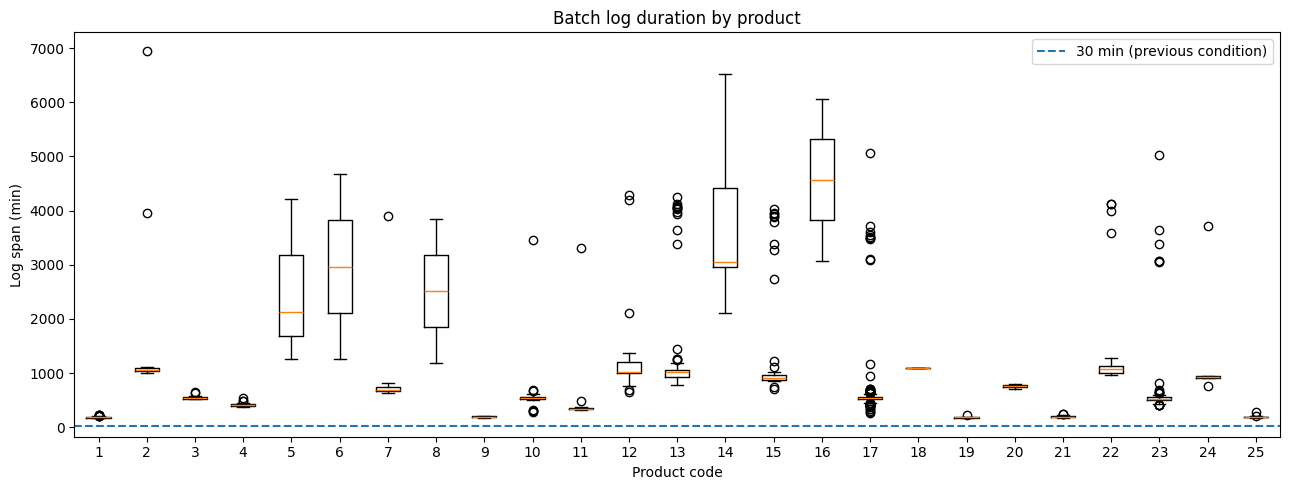

In [4]:
duration = audit.groupby('code').duration_min.agg(batch_n='size', valid_n='count', min='min', q25=lambda s:s.quantile(.25), median='median', mean='mean', q75=lambda s:s.quantile(.75), max='max', std='std')
duration['under_30_n'] = audit.groupby('code').duration_min.apply(lambda s:s.lt(30).sum())
duration['under_30_pct_valid'] = 100 * duration.under_30_n / duration.valid_n.replace(0, np.nan)
duration.to_csv(OUT / 'duration_by_product.csv')
display(duration.round(2))
print('전체 30분 미만:', audit.duration_min.lt(30).sum())
print('기존 ML 제품 30분 미만:', audit.loc[audit.code.isin(ML_CODES), 'duration_min'].lt(30).sum())
print('수행시간 누락:', audit.duration_min.isna().sum())
fig, ax = plt.subplots(figsize=(13,5))
series = [g.duration_min.dropna() for _,g in audit.groupby('code')]
labels = [str(c) for c,_ in audit.groupby('code')]
ax.boxplot(series, tick_labels=labels, showfliers=True)
ax.axhline(30, linestyle='--', label='30 min (previous condition)')
ax.set(xlabel='Product code', ylabel='Log span (min)', title='Batch log duration by product')
ax.legend(); fig.tight_layout(); fig.savefig(OUT/'duration_by_product.png',dpi=150); plt.show()

## 3. 기존 시간순 분할 재현
기존 코드는 로그 종료 순서의 60% 위치를 분할 시각으로 선택한다. 분할 시각 이전 종료 배치는 Train, 해당 시각 이후(포함) 시작 배치는 Test로 두고 그 사이에 걸친 배치는 제외한다. 여기서는 30분 필터를 별도로 비교하되 새 분석의 필수 조건으로 적용하지 않는다.

In [5]:
base = audit[audit.code.isin(ML_CODES)].dropna(subset=['start_ts','end_ts','tbl_yield']).sort_values(['end_ts','batch']).copy()
assert len(base)>1
cut = base.end_ts.iloc[int(len(base)*.6)]
base['phase'] = np.select([base.end_ts.lt(cut), base.start_ts.ge(cut)], ['train','test'], default='boundary')
print('분할 기준:', cut)
display(pd.crosstab(base.code,base.phase).reindex(columns=['train','test','boundary'],fill_value=0))
print('기존 30분 조건 적용 시:')
display(pd.crosstab(base.loc[base.duration_min.ge(30),'code'],base.loc[base.duration_min.ge(30),'phase']).reindex(columns=['train','test','boundary'],fill_value=0))
print('기존 30분 조건 제외 대상:')
display(base.loc[base.duration_min.lt(30), KEY+['phase','duration_min','tbl_yield']])
base[cols+['phase']].to_csv(OUT/'previous_split_audit.csv',index=False)
split = base[base.phase.isin(['train','test'])].copy()
assert split.loc[split.phase.eq('train'),'end_ts'].lt(cut).all()
assert split.loc[split.phase.eq('test'),'start_ts'].ge(cut).all()
assert not split.duplicated(KEY).any()

분할 기준: 2020-10-19 02:16:00


phase,train,test,boundary
code,,,
13,70,60,1
17,119,88,0
23,126,61,0


기존 30분 조건 적용 시:


phase,train,test,boundary
code,,,
13,70,60,1
17,119,88,0
23,126,61,0


기존 30분 조건 제외 대상:


,batch,code,phase,duration_min,tbl_yield


## 4. Train/Test 균일성 점검
제품별 배치 수, 각 집합 내 제품 비율, 수율 평균/표준편차/분위수, 수행시간 및 저수율 배치 비율을 비교한다. 저수율은 여기서 Train의 제품별 하위 10% 분위수 미만이라는 가상 기준이며 실제 승인 규격이나 공식 일탈이 아니다.

phase,train,test
code,,
13,70,60
17,119,88
23,126,61


phase,train,test
code,,
13,22.22,28.71
17,37.78,42.11
23,40.00,29.19


phase,train,test
code,,
13,53.85,46.15
17,57.49,42.51
23,67.38,32.62


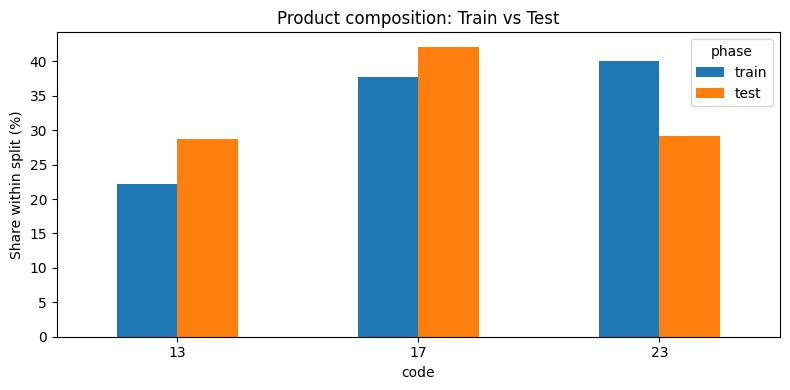

n  yield_mean  yield_std  yield_min  yield_q10  yield_median  \
code phase                                                                   
13   test    60      98.687      0.551     96.506     97.854        98.863   
     train   70      98.778      0.747     95.261     97.815        99.053   
17   test    88      98.524      1.262     87.973     97.860        98.655   
     train  119      98.639      0.762     95.691     97.605        98.866   
23   test    61      98.406      0.707     96.216     97.448        98.578   
     train  126      98.473      0.864     93.797     97.560        98.674   

            duration_median  duration_std  proxy_n  proxy_rate  campaign_n  
code phase                                                                  
13   test            1013.5       772.683        5       0.083           9  
     train           1017.0       832.180        7       0.100          11  
17   test             531.5       774.526        5       0.057          14  
     train            537.0       597.322       12       0.101          16  
23   test             495.0       684.389        7       0.115          10  
     train            533.0       475.149       13       0.103          21

phase          test  train
code campaign             
13   1            0      1
     2            0      1
     14           0      0
     39           0      0
     48           0      3
...             ...    ...
23   183          0      0
     184          0      0
     185          5      0
     186          0      0
     187          0      0

[222 rows x 2 columns]

In [6]:
counts = pd.crosstab(split.code,split.phase).reindex(columns=['train','test'],fill_value=0)
composition = counts.div(counts.sum(axis=0),axis=1)*100
ratio_by_product = counts.div(counts.sum(axis=1),axis=0)*100
display(counts); display(composition.round(2)); display(ratio_by_product.round(2))
counts.to_csv(OUT/'split_counts.csv'); composition.to_csv(OUT/'split_composition_pct.csv')
ax = composition.plot.bar(figsize=(8,4),rot=0)
ax.set(ylabel='Share within split (%)', title='Product composition: Train vs Test')
ax.figure.tight_layout(); ax.figure.savefig(OUT/'split_product_composition.png',dpi=150); plt.show()
q10 = split.loc[split.phase.eq('train')].groupby('code').tbl_yield.quantile(.1)
split['train_q10_proxy'] = split.code.map(q10)
split['below_train_q10'] = split.tbl_yield.lt(split.train_q10_proxy).where(split.train_q10_proxy.notna())
summary = split.groupby(['code','phase']).agg(n=('tbl_yield','size'),yield_mean=('tbl_yield','mean'),yield_std=('tbl_yield','std'),yield_min=('tbl_yield','min'),yield_q10=('tbl_yield',lambda s:s.quantile(.1)),yield_median=('tbl_yield','median'),duration_median=('duration_min','median'),duration_std=('duration_min','std'),proxy_n=('below_train_q10','sum'),proxy_rate=('below_train_q10','mean'),campaign_n=('campaign','nunique'))
summary.to_csv(OUT/'split_distribution_summary.csv'); display(summary.round(3))
display(pd.crosstab([split.code,split.campaign],split.phase,dropna=False))

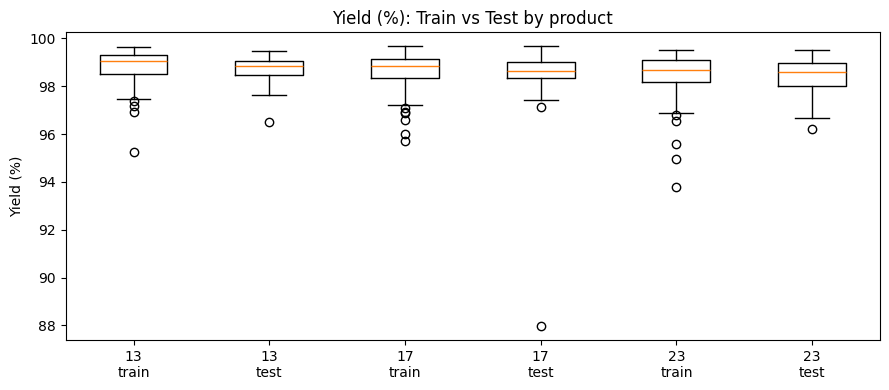

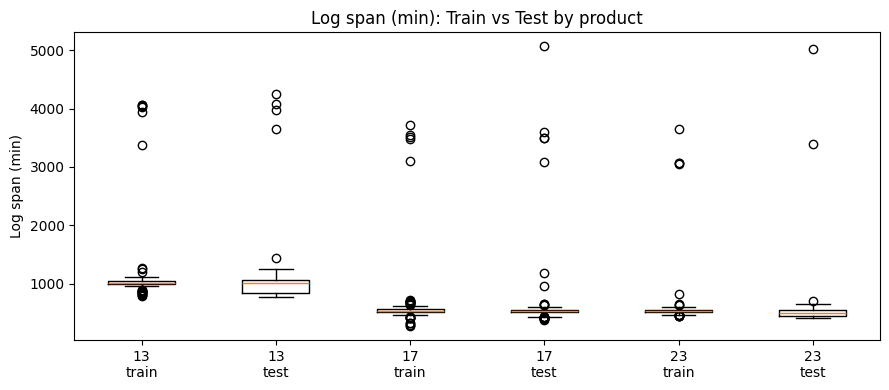

결과 저장 위치: /Users/park-inki/Desktop/SKALA-yield-model/yield_experiment/results/revision_20261125/01_batch_audit_v2


In [7]:
for col, ylabel in [('tbl_yield','Yield (%)'), ('duration_min','Log span (min)')]:
    fig, ax = plt.subplots(figsize=(9,4))
    values=[]; labels=[]
    for c in ML_CODES:
        for phase in ['train','test']:
            values.append(split.loc[split.code.eq(c)&split.phase.eq(phase),col].dropna())
            labels.append(f'{c}\n{phase}')
    ax.boxplot(values,tick_labels=labels,showfliers=True)
    ax.set(ylabel=ylabel,title=f'{ylabel}: Train vs Test by product')
    fig.tight_layout(); fig.savefig(OUT/f'split_{col}_boxplot.png',dpi=150); plt.show()
print('결과 저장 위치:',OUT)

## 5. 결과 해석 및 다음 단계 (실행 결과 확인 후 작성)
- 제품별 로그 수행시간 및 배치 간 차이: 미확인
- 30분 필터 적용/제외 시 배치 수 차이: 미확인
- Train/Test 제품 구성, 수율 및 저수율 비율 차이: 미확인
- Campaign/시간 경계 및 데이터 가용성 확인: 미확인
- 다음 Notebook: 예측 시점 정의 → 당시 확보 가능한 입력변수 검증 → 과거 데이터만 사용하는 시계열 반복 검증 및 기준 모델 비교

주의: 분포 차이를 줄이기 위해 미래 데이터를 학습에 섞지 않는다. 기존 Test는 이미 탐색된 데이터이므로 새 독립 평가셋이 없으면 결과를 탐색적/내부 검증으로 명시한다.
- v2 추가 점검: `timestamp_quality_audit.csv`의 모든 행이 정상 변환되었는지, `duration_by_product.csv`의 valid_n이 batch_n과 일치하는지 확인한다. `sampling_interval_by_product.csv`는 배치별 시각 간격 중앙값의 제품별 요약이다.